# 🏡 Min-Max Normalization Workshop
## Team Name/Number: 6
## Team Members: Jasper Lim
---

## ❗ Why We Normalize: The Problem with Raw Feature Scales

In housing data, features like `Price` and `Lot_Size` can have values in the hundreds of thousands, while others like `Num_Bedrooms` range from 1 to 5. This creates problems when we use algorithms that depend on numeric magnitudes.

---

### ⚠️ What Goes Wrong Without Normalization

---

### 1. 🧭 K-Nearest Neighbors (KNN)

KNN uses the **Euclidean distance** formula:

$$
d = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2 + \cdots}
$$

**Example:**

- $ \text{Price}_1 = 650{,}000, \quad \text{Price}_2 = 250{,}000 $
- $ \text{Bedrooms}_1 = 3, \quad \text{Bedrooms}_2 = 2 $

Now compute squared differences:

$$
(\text{Price}_1 - \text{Price}_2)^2 = (650{,}000 - 250{,}000)^2 = (400{,}000)^2 = 1.6 \times 10^{11}
$$
$$
(\text{Bedrooms}_1 - \text{Bedrooms}_2)^2 = (3 - 2)^2 = 1
$$

➡️ **Price dominates the distance calculation**, making smaller features like `Bedrooms` irrelevant.

---

### 2. 📉 Linear Regression

Linear regression estimates:

$$
y = \beta_1 \cdot \text{Price} + \beta_2 \cdot \text{Bedrooms} + \beta_3 \cdot \text{Lot\_Size} + \epsilon
$$

If `Price` has very large values:
- Gradient updates for $ \beta_1 $ will be **much larger**
- Gradient updates for $ \beta_2 $ (Bedrooms) will be **very small**

➡️ The model overfits high-magnitude features like `Price`.

---

### 3. 🧠 Neural Networks

A single neuron computes:

$$
z = w_1 \cdot \text{Price} + w_2 \cdot \text{Bedrooms} + w_3 \cdot \text{Lot\_Size}
$$

If:

- $ \text{Price} = 650{,}000 $
- $ \text{Bedrooms} = 3 $
- $ \text{Lot\_Size} = 8{,}000 $

Then:

$$
z \approx w_1 \cdot 650{,}000 + w_2 \cdot 3 + w_3 \cdot 8{,}000
$$

➡️ Even with equal weights, `Price` contributes **most of the activation**, making it difficult for the network to learn from other features.

---

### ✅ Solution: Min-Max Normalization

We apply the transformation:

$$
x_{\text{normalized}} = \frac{x - x_{\text{min}}}{x_{\text{max}} - x_{\text{min}}}
$$

This scales all features to a common range (typically $[0, 1]$).

| Feature      | Raw Value | Min     | Max     | Normalized Value |
|--------------|-----------|---------|---------|------------------|
| Price        | 650,000   | 250,000 | 800,000 | 0.72             |
| Bedrooms     | 3         | 1       | 5       | 0.50             |
| Lot_Size     | 8,000     | 3,000   | 10,000  | 0.714            |

➡️ Now, **each feature contributes fairly** to model training or distance comparisons.

---

## 📌 Use Case: Housing Data
We are normalizing features from a real estate dataset to prepare it for machine learning analysis.

In [2]:
# 🔢 Load and display dataset
import pandas as pd
df = pd.read_csv('./data/housing_data.csv')
df.head()

,House_ID,Price,Area_sqft,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size
0,H100000,574507,1462,3,3,2002,4878
1,H100001,479260,1727,2,2,1979,4943
2,H100002,597153,1403,5,2,1952,5595
3,H100003,728454,1646,5,2,1992,9305
4,H100004,464876,853,1,1,1956,7407


### 🔎 Step 1 — Implement Min-Max Normalization on the Housing Dataset

In [ ]:
# Apply Min-Max normalization manually to every numeric column.
# A constant column uses a safe denominator of 1, so its normalized values are all 0.
numeric_columns = df.select_dtypes(include="number").columns
xmin = df[numeric_columns].min()
xmax = df[numeric_columns].max()
feature_ranges = (xmax - xmin).replace(0, 1)
df_normalized = (df[numeric_columns] - xmin) / feature_ranges

assert ((df_normalized >= 0) & (df_normalized <= 1)).all().all()
print(f"Normalized {len(numeric_columns)} numeric columns: {numeric_columns.tolist()}")
display(df_normalized.head())

Price            1077909
Area_sqft           3763
Num_Bedrooms           5
Num_Bathrooms          3
Year_Built          2022
dtype: int64

### 🔎 Talking Points #1 — Why normalization matters

1. **Distance-based models:** Min-Max scaling puts price, lot size, and room counts on the same 0–1 range. Without it, large-unit features dominate Euclidean distance in KNN. Scaling makes their ranges comparable, but does not guarantee that every feature is equally informative.
2. **Gradient-based learning:** Features with very different magnitudes can produce poorly balanced gradients and slow or unstable optimization. A common scale generally makes learning rates easier to tune; normalization does not by itself prevent overfitting.
3. **Sound preprocessing:** The identifier `House_ID` is not a measurement and is excluded. `Price` is normalized for comparison here, but must be excluded from predictors when it is the prediction target. For a train/test workflow, fit min/max values on training data only and reuse them for validation/test data to avoid leakage.


## 🧩 Challenge Extension: After Normalization, Which Features Matter Most?

You’ve normalized the housing features so they share a common scale.  
Now comes a common next step in ML workflows:

> **How do we identify the most important directions (principal components) in the data—and how might these relate to a target variable like `Price`?**

This introduces **Principal Component Analysis (PCA)**.

---

## 📚 PCA Theory (Conceptual)

### What PCA *is*
PCA is an **unsupervised** dimensionality reduction technique that:
- Finds **new axes** (principal components) that are **linear combinations** of your original features.
- Orders these axes so that:
  - **PC1** captures the **most variance** in the feature space,
  - **PC2** captures the next most variance, and so on,
  - Each PC is **orthogonal** (uncorrelated) with the previous ones.

### What PCA is *not*
PCA does **not** directly find features that “impact the target variable” because it does not use the target in its optimization.

However, you *can*:
- Compute PCs from the feature matrix **X** (after normalization),
- Then measure how PCs relate to the target **y** (e.g., correlation with `Price`, or a simple regression on PCs),
- Interpret which original features contribute most to PCs that are most related to **y**.

---

## 🧠 The Math (high level)
Given a centered feature matrix \(X\) (often standardized/normalized first):

1. Compute covariance matrix:
$$
\Sigma = \frac{1}{n-1}X^\top X
$$

2. Find eigenvectors (principal directions) and eigenvalues (variance captured):
$$
\Sigma v_i = \lambda_i v_i
$$

- $ v_i $ are **principal component directions** (loadings)
- $ \lambda_i $ are the **variance explained** by each component

---

## ✅ Why Normalize Before PCA?
PCA is sensitive to scale. Without normalization/standardization:
- A large-scale feature (e.g., `Price`) can dominate variance
- PCs will reflect units rather than structure

---

## 🎯 Student Challenge
Using the **housing dataset**:

1. Apply PCA to the normalized feature matrix \(X\) (exclude ID columns and the target).
2. Determine how many components are needed to explain **≥ 90%** of the variance.
3. Identify which original features contribute most to:
   - **PC1** and **PC2**, and
   - the **PC most correlated with the target** (`Price`).
4. Write a short interpretation:
   - “What does PC1 represent in housing terms?”
   - “Do the PCs that explain the most variance also relate most strongly to `Price`?”



### 🔗 How to Integrate This With Your Step 1 Normalization

- If you created normalized columns (e.g., `Area_sqft_norm`), use those in `candidate_features`.
- If you normalized in-place (overwriting original columns), you can use the original names.
- PCA should **not** include:
  - `House_ID` (identifier)
  - non-numeric categorical columns (unless encoded appropriately)
- Decide intentionally whether to include `Year_Built`:
  - It’s numeric, but it may behave differently than size/price-related features.

---

### ✅ Challenge Findings

1. **Variance threshold:** Four components are needed to reach at least 90% cumulative explained variance (PC1–PC3 explain 88.44%; PC1–PC4 explain 94.86%).
2. **Largest loadings:** `Num_Bathrooms` contributes most to PC1 (loading about -0.999), while `Num_Bedrooms` contributes most to PC2 (about 0.993). Loading signs can flip without changing the component.
3. **Relationship to Price:** PC3 has the largest absolute correlation with raw `Price`, but the correlation is only about -0.032 and is practically negligible in this dataset.
4. **Interpretation:** PC1 is essentially a bathroom-count direction because its loading on `Num_Bathrooms` is much larger than its loadings on the other input features. PCA is unsupervised, so this high-variance direction is not necessarily useful for predicting price.

In [9]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

# Keep Price as the target, not a PCA input; exclude the non-numeric House_ID as well.
target_column = "Price"
excluded_columns = {"House_ID", target_column}
feature_columns = [
    column
    for column in df.select_dtypes(include="number").columns
    if column not in excluded_columns
]
X = df_normalized[feature_columns]
y = df[target_column]

# PCA centers the already normalized input features before finding components.
pca = PCA()
pc_scores = pca.fit_transform(X)
pc_names = [f"PC{i + 1}" for i in range(pca.n_components_)]
explained_variance = pd.Series(pca.explained_variance_ratio_, index=pc_names)
cumulative_variance = explained_variance.cumsum()
components_for_90_percent = int(np.searchsorted(cumulative_variance, 0.90) + 1)

loadings = pd.DataFrame(pca.components_.T, index=feature_columns, columns=pc_names)
target_correlations = pd.Series(
    {
        pc_name: pd.Series(pc_scores[:, index]).corr(y)
        for index, pc_name in enumerate(pc_names)
    },
    name="Correlation with Price",
)
most_price_related_pc = target_correlations.abs().idxmax()

print(f"PCA input features: {feature_columns}")
print(f"Components needed for >= 90% variance: {components_for_90_percent}")
print(f"PC1 largest absolute loading: {loadings['PC1'].abs().idxmax()}")
print(f"PC2 largest absolute loading: {loadings['PC2'].abs().idxmax()}")
print(
    f"Most Price-correlated component: {most_price_related_pc} "
    f"(r = {target_correlations[most_price_related_pc]:.3f})"
)
display(
    pd.DataFrame(
        {
            "Explained variance": explained_variance,
            "Cumulative variance": cumulative_variance,
            "Correlation with Price": target_correlations,
        }
    ).round(3)
)
display(loadings.iloc[:, :2].round(3))

PCA input features: ['Area_sqft', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built', 'Lot_Size']
Components needed for >= 90% variance: 4
PC1 largest absolute loading: Num_Bathrooms
PC2 largest absolute loading: Num_Bedrooms
Most Price-correlated component: PC3 (r = -0.032)


,Explained variance,Cumulative variance,Correlation with Price
PC1,0.396,0.396,-0.011
PC2,0.289,0.685,-0.008
PC3,0.200,0.884,-0.032
PC4,0.064,0.949,0.017
PC5,0.051,1.000,-0.017


,PC1,PC2
Area_sqft,0.002,0.016
Num_Bedrooms,0.052,0.993
Num_Bathrooms,0.999,-0.050
Year_Built,-0.015,0.100
Lot_Size,0.004,-0.018


## 📊 PCA Visualizations

The figure compares cumulative explained variance with the 90% threshold, shows signed feature loadings for the first three components, and plots each component's correlation with the original (unscaled) `Price` target. Component loading signs may reverse because the direction of a PCA axis is arbitrary.

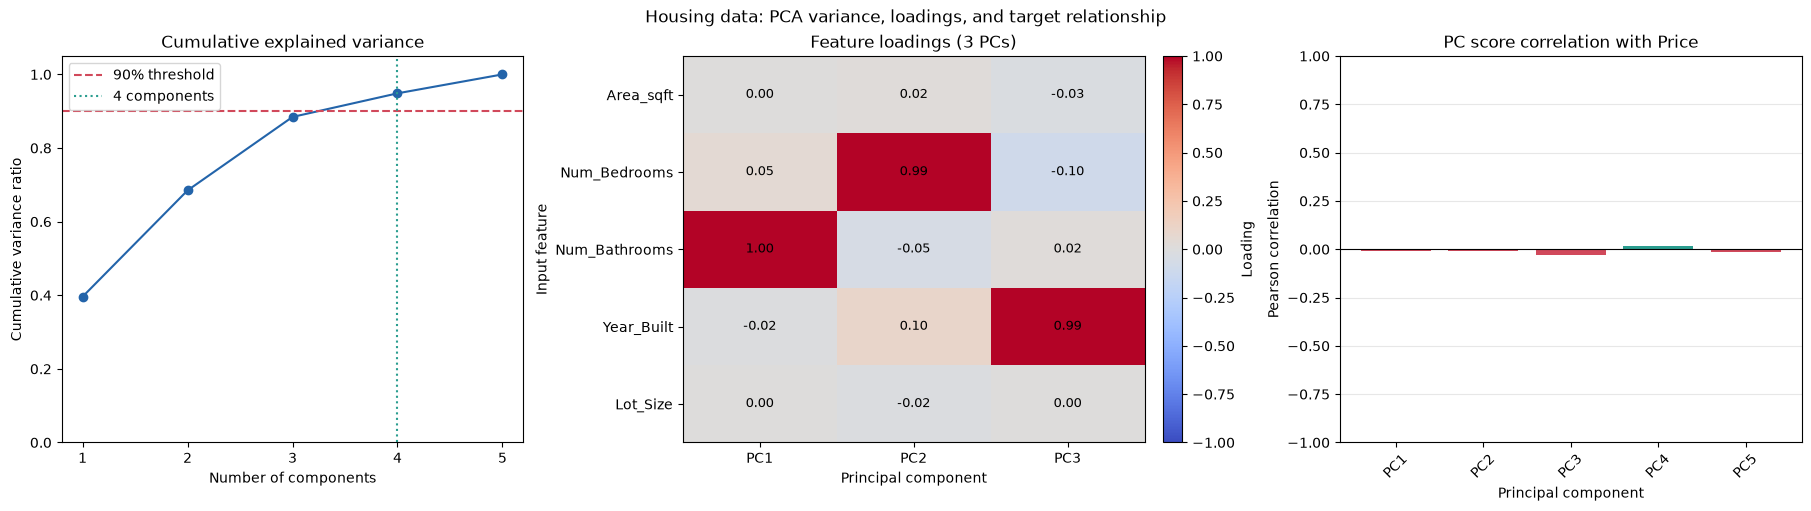

In [10]:
import matplotlib.pyplot as plt

component_numbers = np.arange(1, len(pc_names) + 1)
components_to_show = min(3, len(pc_names))
loadings_to_show = loadings.iloc[:, :components_to_show]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

# Scree-style cumulative variance plot.
axes[0].plot(component_numbers, cumulative_variance, marker="o", color="#2364aa")
axes[0].axhline(0.90, linestyle="--", color="#d1495b", label="90% threshold")
axes[0].axvline(
    components_for_90_percent,
    linestyle=":",
    color="#2a9d8f",
    label=f"{components_for_90_percent} components",
)
axes[0].set(
    title="Cumulative explained variance",
    xlabel="Number of components",
    ylabel="Cumulative variance ratio",
    xticks=component_numbers,
    ylim=(0, 1.05),
)
axes[0].legend()

# Signed loadings indicate each feature's direction and contribution to a PC.
image = axes[1].imshow(loadings_to_show.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
axes[1].set(
    title=f"Feature loadings ({components_to_show} PCs)",
    xlabel="Principal component",
    ylabel="Input feature",
    xticks=range(components_to_show),
    xticklabels=loadings_to_show.columns,
    yticks=range(len(feature_columns)),
    yticklabels=feature_columns,
)
for row in range(len(feature_columns)):
    for column in range(components_to_show):
        axes[1].text(
            column,
            row,
            f"{loadings_to_show.iloc[row, column]:.2f}",
            ha="center",
            va="center",
            fontsize=9,
        )
fig.colorbar(image, ax=axes[1], fraction=0.046, pad=0.04, label="Loading")

# Keep the full correlation scale so near-zero relationships are visible as weak.
correlation_colors = [
    "#2a9d8f" if value >= 0 else "#d1495b"
    for value in target_correlations
]
axes[2].bar(target_correlations.index, target_correlations.values, color=correlation_colors)
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set(
    title="PC score correlation with Price",
    xlabel="Principal component",
    ylabel="Pearson correlation",
    ylim=(-1, 1),
)
axes[2].tick_params(axis="x", rotation=45)
axes[2].grid(axis="y", alpha=0.3)

fig.suptitle("Housing data: PCA variance, loadings, and target relationship")
plt.show()

### 🔎 Talking Points #2 — PCA interpretation

1. **Variance is not the same as predictive value:** PCA is unsupervised and orders components by feature variance, not by how well they explain `Price`. The first three components capture 88.44%, just short of the 90% threshold; the fourth raises the total to 94.86%.
2. **Interpret loadings by magnitude:** PC1 is dominated by `Num_Bathrooms` and PC2 by `Num_Bedrooms`. A component's sign is arbitrary, so the magnitude identifies the strongest contribution; it is not evidence of a causal effect.
3. **The target relationship is weak:** PC3 is most correlated with `Price` (r ≈ -0.032), which is close to zero. The scree plot, loading heatmap, and correlation chart below help show why retaining variance alone does not guarantee useful price predictions.

# 📤 How to Submit the Assignment

Follow these instructions carefully to ensure your team submits a complete and well-organized assignment.

## Step 1: Get the Starter Repository

1. Clone the GitHub repository provided by the instructor.
2. Keep the **original repository name**. Do **not** rename the repository.

## Step 2: Complete the Workshop

3. Create **one shared Jupyter Notebook** for the entire team to work on.
4. At the top of **`MinMax_Normalization_Workshop.ipynb`**, clearly include:
   - Team Number
   - Full Name of each team member
5. Complete **all coding tasks, analyses, and written answers** in the same notebook.
6. Make sure all notebook cells execute successfully before submission.

## Step 3: Update the Project Documentation

7. Replace the existing **`README.md`** file with a new version that:
   - Introduces your team
   - Explains the purpose of the workshop
   - Describes the work you completed
   - Summarizes your findings and conclusions
   - Can be used as the visual aid for your team's **5-minute presentation**

## Step 4: Review Project Dependencies

8. Review the project's Python dependencies and decide whether the **`requirements.txt`** file needs to be updated.
   - If you installed additional packages, regenerate or update the file.
   - If no new dependencies were added, no changes may be necessary.

## Step 5: Publish Your Work

9. Push the completed repository to your own GitHub account.
10. Verify that all files have been uploaded correctly and that the repository is publicly accessible if required by the instructor.

---

## ✅ Submission Checklist

Before submitting, confirm that the following items are complete:

- [ ] Repository name has not been changed
- [ ] `MinMax_Normalization_Workshop.ipynb` contains all required work
- [ ] Team number and team member names appear at the top of the notebook
- [ ] All questions have been answered
- [ ] All code runs successfully
- [ ] `README.md` has been replaced with a project summary
- [ ] README can support a 5-minute presentation
- [ ] `requirements.txt` has been reviewed and updated if necessary
- [ ] Repository has been pushed to your GitHub account
- [ ] Final work has been reviewed by all team members

> **Important:** Submit a repository that is clean, complete, and easy to understand. The notebook and README should clearly demonstrate your team's work, findings, and understanding of Min-Max Normalization.